<a href="https://colab.research.google.com/github/teddyschwartzy/final_project/blob/main/Final_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Final Project**
## Predicting Mortality Outcomes in HIV/AIDS Patients

**Author:** Hunter Schwarz

---

**Dataset:** AIDS Clinical Trials Group Study 175 (ACTG 175)

**Description:** The ACTG 175 dataset contains clinical trial data from individuals living with HIV/AIDS, including demographic characteristics, treatment information, and baseline clinical measurements. In this project, the objective is to predict mortality outcomes by classifying patients as either deceased or alive/censored using the available clinical predictors.

**Notebook Purpose:** The goal of this notebook is to develop and evaluate a modular, automated analysis pipeline that incorporates data ingestion, data quality assessment, descriptive and exploratory analysis, inferential statistical testing, and comparative machine learning model evaluation. The workflow is designed to promote reproducibility while demonstrating the application of data science methods to a real-world clinical dataset.

**Note:** This dataset is used for instructional and demonstration purposes only.

### Project Overview

The purpose of this project is to create an automated pipeline for predicting mortality outcomes in patients from the ACTG 175 clinical trial. Building on the refactoring work from earlier weeks, I converted the analysis from a linear notebook into a modular, class-based workflow that handles data ingestion, preprocessing, statistical testing, and machine learning evaluation in a consistent and reproducible manner.

Automating these steps makes the analysis easier to maintain, reproduce, and expand while helping identify the clinical variables most closely associated with patient survival. More broadly, this project highlights how structured programming practices can improve the quality and reliability of health data science analyses.

### Workflow

The pipeline executes the following stages in order:

1. **Data Import & Validation** — Loads the dataset from the UCI Repository (or a user upload) and runs automated profiling and clinical range checks.
2. **Descriptive Statistics** — Summarizes central tendency and dispersion for all numeric variables.
3. **Exploratory Data Analysis** — Produces visualizations of the outcome distribution, key clinical predictors, and survival experience.
4. **Inferential Statistics** — Tests the statistical significance of the relationship between selected predictors and the outcome.
5. **Preprocessing & Feature Engineering** — Encodes categoricals, creates an interaction term, and splits, imputes, and scales the data.
6. **Model Training & Evaluation** — Trains four supervised classifiers and evaluates them on a held-out test set with cross-validation.
7. **Interpretation** — Selects a champion model using a predefined primary metric and interprets the results in clinical context.

### How to Run

- **Default:** Run all cells from top to bottom. The dataset is fetched automatically from the UCI Machine Learning Repository.
- **Optional:** To upload your own copy of the dataset from your local environment, change `"data_source"` to `"local"` in the CONFIG cell.

In [1]:
# 1. ENVIRONMENT SETUP

# To ensure reproducibility, you may uncomment the line below to pin specific versions
# !pip install pandas==2.2.3 numpy==2.1.3 matplotlib==3.10.0 seaborn==0.13.2 scipy==1.16.3 ucimlrepo==0.0.7
# Note: scikit-learn ships with Colab; check the version printed below and add it into requirements.txt within the repository

# Install the UCI repository connector used to fetch the ACTG 175 dataset
!pip install -q ucimlrepo

# Data manipulation
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

# Statistical testing
import scipy as sp
from scipy import stats

# Machine learning
import sklearn as sk
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
)

# UCI Machine Learning Repository connector
from ucimlrepo import fetch_ucirepo

# Helper used to display styled tables in both Colab and local Jupyter
from IPython.display import display

# Global visual settings, can be modified for preference
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Global random seed so every run produces identical results
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Verify the environment so another user can confirm the setup matches
print("Environment Verified:")
print(f"- Pandas: {pd.__version__}")
print(f"- NumPy: {np.__version__}")
print(f"- Matplotlib: {mpl.__version__}")
print(f"- Seaborn: {sns.__version__}")
print(f"- SciPy: {sp.__version__}")
print(f"- Scikit-learn: {sk.__version__}")

Environment Verified:
- Pandas: 2.2.3
- NumPy: 2.1.3
- Matplotlib: 3.10.0
- Seaborn: 0.13.2
- SciPy: 1.16.3
- Scikit-learn: 1.6.1


In [2]:
# 2. CONFIGURATION

# Central configuration dictionary for the analysis
CONFIG = {
    # --- Data source settings ---
    # Set to "api" to fetch ACTG 175 from the UCI Repository or set to "local" to upload your own copy from your computer
    "data_source": "api",
    # UCI repository identifier for the ACTG 175 dataset
    "dataset_id": 890,
    # Name of the binary outcome column
    "target_column": "target",

    # Significance level used for all inferential tests
    "significance_level": 0.05,

    # Proportion of data reserved for the held-out test set
    "test_size": 0.3,
    # Predefined primary metric used to select the champion model: AUC is preferred over accuracy because the outcome is class-imbalanced
    "primary_metric": "AUC",
    # Number of cross-validation folds used to check result stability
    "cv_folds": 5,

    # If the event rate falls below this proportion, the pipeline enables balanced class weighting for Logistic Regression
    "imbalance_threshold": 0.40,

    # Values outside these ranges are treated as implausible and set to missing.
    "data_dictionary": {
        "age":         {"label": "Age (years)",                "min": 10,  "max": 100},
        "weight":      {"label": "Weight (kg)",                "min": 30,  "max": 300},
        "cd40":        {"label": "Baseline CD4 (cells/uL)",    "min": 0,   "max": 2000},
        "cd420":       {"label": "CD4 at 20 wks (cells/uL)",   "min": 0,   "max": 2000},
        "cd80":        {"label": "Baseline CD8 (cells/uL)",    "min": 0,   "max": 10000},
        "cd820":       {"label": "CD8 at 20 wks (cells/uL)",   "min": 0,   "max": 10000},
        "hemoglobin":  {"label": "Hemoglobin (g/dL)",          "min": 0,   "max": 30},
        "kps":         {"label": "Karnofsky Score",            "min": 0,   "max": 100},
        "ln89hiv":     {"label": "Log10 HIV RNA",              "min": 0,   "max": 8},
    },
}

### Pipeline Design and Adaptive Behavior

In previous assignments, the analysis was completed through a series of linear notebook cells. For this final project, I reorganized the code into a single class-based pipeline (`HealthAnalysisPipeline`) so that the data, preprocessing objects, and model outputs are stored as instance state. This keeps the training and testing datasets separate, applies the same imputation and scaling learned from the training set to the test set, and removes the risk of running notebook cells out of order. The class design also makes the project easier to extend: new clinical variables, preprocessing steps, or machine learning models can be added without rewriting the underlying data-preparation logic.

Beyond the class structure, the pipeline adapts to dataset characteristics and user-defined goals at the following points:

1. **Modular pipeline refactoring** — Each stage is a method, and a `run()` orchestrator executes them in a fixed sequence, making the workflow reproducible and scalable for other clinical datasets.
2. **Automated data quality validation** — Reports class imbalance, missing values, and duplicate rows, and checks numeric variables against a clinical data dictionary of plausible ranges. *Adaptive:* dictionary columns that are not present in the uploaded data are skipped, so the same validation stage runs on other clinical datasets.
3. **Adaptive feature engineering** — Categorical columns are encoded only if they are present, and a CD4 x age interaction term is created only if both source variables exist, capturing non-linear relationships that may be clinically significant in predicting mortality.
4. **Programmatic model selection** — Rather than comparing results manually, the pipeline trains four models — Logistic Regression, Decision Tree, Random Forest, and Gradient Boosting — and automatically identifies the best-performing model based on a predefined primary metric (ROC-AUC), removing subjectivity from the selection process. *Adaptive:* if the event rate falls below the configured threshold, Logistic Regression is retrained with balanced class weighting.
5. **Cross-validation stability check** — A 5-fold cross-validation score is added for each model, providing a stability check on the single-split estimates, which can be optimistic or pessimistic.
6. **Expanded evaluation suite** — A ROC curve overlay, a confusion matrix for the champion model, a grouped comparison of classification metrics, and Random Forest feature importance provide a more accurate measure of sensitivity and specificity than accuracy alone when clinical outcomes are imbalanced.

In [3]:
# 3. HEALTH ANALYSIS PIPELINE

# A modular pipeline for the ACTG 175 mortality analysis. The class stores the data, preprocessing objects, and model outputs as instance attributes so that each stage can access the results of the previous stage in a consistent and reproducible manner.
class HealthAnalysisPipeline:

    def __init__(self, config):
        # Store the configuration dictionary for all pipeline stages
        self.config = config

        # Initialize the data and model state as empty
        self.df = None
        self.feature_columns = []
        self.X_train, self.X_test = None, None
        self.y_train, self.y_test = None, None
        self.results = {}
        self.champion = None

        # Preprocessing objects are fitted on the training set only
        self.imputer = SimpleImputer(strategy="median")
        self.scaler = StandardScaler()

        # Define the supervised classification models to compare
        self.models = {
            "Logistic Regression": LogisticRegression(
                max_iter=1000, random_state=RANDOM_STATE
            ),
            "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
            "Random Forest": RandomForestClassifier(
                n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1
            ),
            "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
        }
    # Load the dataset from the UCI Repository or a local upload, then run automated profiling and validation checks.
    def ingest_and_validate(self):
        print("--- Step 1: Data Ingestion & Validation ---")

        # Read the chosen data source from the configuration
        source = self.config["data_source"]

        # Branch 1: fetch the dataset from the UCI Repository
        if source == "api":
            try:
                # Print a status message before the network call
                print("Fetching dataset from the UCI Repository...")
                # Fetch the dataset by its UCI repository identifier
                data = fetch_ucirepo(id=self.config["dataset_id"])
                # Copy the predictor table so the original data is not modified
                self.df = data.data.features.copy()
                # Append the binary outcome as a new column
                self.df[self.config["target_column"]] = data.data.targets
            except Exception as error:
                # Raise a clear message if the network fetch fails
                raise ConnectionError(
                    "Unable to fetch the dataset from the UCI Repository. "
                    "Check your internet connection, or set data_source to 'local'. "
                    f"Original error: {error}"
                )

        # Branch 2: upload a dataset from the user's local environment
        elif source == "local":
            # Import the Colab file upload helper inside the branch
            from google.colab import files

            # Prompt the user to choose a file from their computer
            print("Please upload your CSV file:")
            uploaded = files.upload()

            # Use the name of the first uploaded file
            file_name = list(uploaded.keys())[0]

            # Load the uploaded file into a DataFrame
            self.df = pd.read_csv(uploaded[file_name])

            # Confirm the uploaded file contains the expected outcome column
            if self.config["target_column"] not in self.df.columns:
                raise ValueError(
                    f"Local CSV must contain a '{self.config['target_column']}' column."
                )

        # Guard against invalid configuration values
        else:
            raise ValueError("data_source must be set to 'api' or 'local'.")

        # Confirm successful ingestion with the dataset dimensions
        print(f"Dataset loaded: {self.df.shape[0]} rows x {self.df.shape[1]} columns\n")

        # Complete data profiling
        # 1. Class balance of the outcome variable
        balance = self.df[self.config["target_column"]].value_counts(normalize=True)
        print("Target class balance:")
        print(balance.to_string())
        print()

        # 2. Missing values by column
        missing = self.df.isna().sum()
        missing = missing[missing > 0]
        if missing.empty:
            # Report a clean dataset when no gaps exist
            print("No missing values detected in the raw data.")
        else:
            # Report the columns that will later require imputation
            print("Columns containing missing values:")
            print(missing.to_string())
        print()

        # 3. Duplicate row check
        duplicates = self.df.duplicated().sum()
        if duplicates > 0:
            # Remove exact duplicates and report the number removed
            self.df = self.df.drop_duplicates().reset_index(drop=True)
            print(f"Removed {duplicates} duplicate rows.")
        else:
            print("No duplicate rows detected.")
        print()

        # 4. Clinical plausibility checks using the data dictionary
        print("Clinical range validation:")
        for column, rules in self.config["data_dictionary"].items():
            # Skip any variable that is not present in the dataset
            if column not in self.df.columns:
                continue

            # Identify values that fall outside the plausible clinical range
            out_of_range = (self.df[column] < rules["min"]) | (self.df[column] > rules["max"])

            # Report how many values were flagged for this variable
            print(f"  {rules['label']}: {out_of_range.sum()} implausible values")

            # Convert implausible values to missing so imputation handles them
            if out_of_range.sum() > 0:
                self.df.loc[out_of_range, column] = np.nan
        print()

        # 5. Confirm the outcome variable is binary and coded 0/1
        unique_outcomes = sorted(self.df[self.config["target_column"]].dropna().unique())
        if unique_outcomes != [0, 1]:
            raise ValueError(
                f"Expected a binary outcome coded 0/1, found: {unique_outcomes}"
            )

        # Confirm that validation completed successfully
        print("Validation complete: the dataset passed all structural checks.\n")

    # Generate a descriptive statistics table for all numeric variables.
    def run_descriptive(self):
        print("--- Step 2: Descriptive Statistics ---")

        # Build a transposed summary table so each variable is a row
        summary = (
            self.df
            .select_dtypes(include="number")
            .describe()
            .T
            .round(2)
        )

        # Reorder the columns into a clinically friendly sequence
        summary = summary[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]

        # Display the table with bold headers and centered values
        display(
            summary.style
            .set_table_styles([
                {"selector": "th", "props": [("font-weight", "bold"), ("text-align", "center")]},
                {"selector": "td", "props": [("text-align", "center")]},
            ])
        )
        print()

    # Produce exploratory visualizations that tell the story of the cohort.
    def run_eda(self):
        print("--- Step 3: Exploratory Data Analysis ---")
        # Read the outcome column name from the configuration
        target = self.config["target_column"]

        # 1. Distribution of the mortality outcome (class balance)
        plt.figure(figsize=(6, 4))
        sns.countplot(x=target, data=self.df, hue=target, palette="viridis", legend=False)
        plt.title("Distribution of Mortality Outcome")
        plt.xlabel("Outcome (0 = Alive/Censored, 1 = Death)")
        plt.ylabel("Number of Patients")
        plt.show()

        # 2. Age by outcome: distribution overlap and spread between groups
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        # Histogram with density curves shows where the groups overlap
        sns.histplot(data=self.df, x="age", hue=target, kde=True, ax=axes[0], palette="viridis")
        axes[0].set_title("Age Distribution by Outcome")
        # Boxplot highlights variance and outliers between groups
        sns.boxplot(data=self.df, x=target, y="age", hue=target, ax=axes[1], palette="viridis", legend=False)
        axes[1].set_title("Age Variance by Outcome")
        plt.tight_layout()
        plt.show()

        # 3. Baseline CD4 count by outcome, the central immune marker in HIV
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        sns.histplot(data=self.df, x="cd420", hue=target, kde=True, ax=axes[0], palette="magma")
        axes[0].set_title("CD4 at 20 Weeks by Outcome")
        sns.boxplot(data=self.df, x=target, y="cd420", hue=target, ax=axes[1], palette="magma", legend=False)
        axes[1].set_title("CD4 at 20 Weeks Variance by Outcome")
        plt.tight_layout()
        plt.show()

        # 4. Correlation heatmap of the numeric clinical variables
        plt.figure(figsize=(14, 10))
        # Use all numeric columns except the outcome
        numeric_cols = self.df.select_dtypes(include="number").columns.drop(target, errors="ignore")
        # Annotate the cells with a compact floating-point format
        sns.heatmap(self.df[numeric_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 8})
        plt.title("Pearson Correlation Matrix of Clinical Variables")
        plt.tight_layout()
        plt.show()

        # 5. Kaplan-Meier survival estimate by treatment arm
        self._plot_kaplan_meier()
        print()

    # Estimate and plot the Kaplan-Meier survival curve for each treatment arm using the time-to-event variable (days).
    def _plot_kaplan_meier(self):
        target = self.config["target_column"]

        # Keep only patients with a recorded follow-up time and treatment arm
        surv = self.df.dropna(subset=["time", "trt", target])

        # Map treatment arm codes to the ACTG 175 protocol arms
        arm_labels = {0: "Placebo", 1: "ZDV 1200 mg", 2: "ZDV 1800 mg", 3: "ddI (didanosine)"}

        plt.figure(figsize=(9, 5))
        # Repeat the estimation for each treatment arm
        for arm in sorted(surv["trt"].unique()):
            # Subset the patients in the current treatment arm
            group = surv[surv["trt"] == arm]

            # Sort the unique follow-up times in ascending order
            event_times = np.sort(group["time"].unique())

            # Kaplan-Meier estimator: S(t) = product over t' <= t of (1 - d(t')/n(t'))
            survival = 1.0
            x_points, y_points = [0], [1.0]
            for t in event_times:
                # Number of patients still under observation at time t
                n_at_risk = (group["time"] >= t).sum()
                # Number of patients who experienced the event at time t
                d = ((group["time"] == t) & (group[target] == 1)).sum()

                # Update the survival estimate only when an event occurs at t
                if n_at_risk > 0 and d > 0:
                    survival *= (1 - d / n_at_risk)

                # Record the step in the survival curve
                x_points.append(t)
                y_points.append(survival)

            # Draw the step line for the current arm with its sample size
            label = arm_labels.get(arm, f"Arm {arm}")
            plt.step(x_points, y_points, where="post", label=f"{label} (n={len(group)})")

        # Label the axes and display the figure
        plt.xlabel("Time (days)")
        plt.ylabel("Estimated Probability of Survival")
        plt.title("Kaplan-Meier Survival Estimate by Treatment Arm")
        plt.legend()
        plt.show()

    # Run inferential statistical tests to identify predictors with a statistically significant relationship to the outcome.
    def run_inferential_stats(self):
        print("--- Step 4: Inferential Statistical Analysis ---")
        # Read the outcome column and significance level from the configuration
        target = self.config["target_column"]
        alpha = self.config["significance_level"]

        # Split the data into the two outcome groups for comparison
        group0 = self.df[self.df[target] == 0]
        group1 = self.df[self.df[target] == 1]

        # Collect each test's label, statistic, and p-value
        tests = []

        # Method 1: independent-samples t-test for age
        t_stat, p_t = stats.ttest_ind(group0["age"].dropna(), group1["age"].dropna())
        tests.append(("Independent t-test (Age)", t_stat, p_t))

        # Method 2: chi-square test of independence for gender
        table = pd.crosstab(self.df["gender"], self.df[target])
        chi2, p_chi, dof, expected = stats.chi2_contingency(table)
        tests.append(("Chi-square (Gender)", chi2, p_chi))

        # Method 3: one-way ANOVA for baseline CD4 across treatment arms
        if "trt" in self.df.columns:
            arms = [g["cd420"].dropna() for _, g in self.df.groupby("trt")]
            f_stat, p_anova = stats.f_oneway(*arms)
            tests.append(("One-way ANOVA (CD4 at 20 weeks by Treatment Arm)", f_stat, p_anova))
        else:
            print("[Info] 'trt' not present. Skipping ANOVA.")

        # Assemble the test results into a summary table
        summary = pd.DataFrame(tests, columns=["Test", "Statistic", "p-value"])

        # Interpret each test against the configured significance level
        summary["Significant"] = np.where(summary["p-value"] < alpha, "Yes", "No")

        # Display the table with the same styling used for other results
        display(
            summary.style
            .format({"Statistic": "{:.4f}", "p-value": "{:.4f}"})
            .set_table_styles([
                {"selector": "th", "props": [("font-weight", "bold"), ("text-align", "center")]},
                {"selector": "td", "props": [("text-align", "center")]},
            ])
        )

        # Print a plain-language conclusion based on the results
        significant = summary[summary["Significant"] == "Yes"]
        if not significant.empty:
            print("\nResult: The following tests show a statistically significant relationship with the outcome:")
            for _, row in significant.iterrows():
                print(f"  - {row['Test']} (p = {row['p-value']:.4f})")
        else:
            print("\nResult: No tests met the significance threshold in this cohort.")
        print()

    # Encode categorical variables, engineer features, split the data, and impute and scale the predictors.
    def preprocess_data(self):
        print("--- Step 5: Preprocessing & Feature Engineering ---")
        # Work on a copy so the original validated data is preserved
        df_proc = self.df.copy()

        # 1. Encode categorical variables (only if present)
        cat_cols = df_proc.select_dtypes(include=["object", "category"]).columns
        if len(cat_cols) > 0:
            # Apply label encoding to each categorical column
            encoder = LabelEncoder()
            for col in cat_cols:
                df_proc[col] = encoder.fit_transform(df_proc[col].astype(str))
            print(f"Encoded categorical columns: {list(cat_cols)}")
        else:
            # All predictors are already numeric, so no encoding is required
            print("No categorical columns detected; skipping encoding.")

        # 2. Remove the time-to-event variable from the predictors
        if "time" in df_proc.columns:
            df_proc = df_proc.drop(columns=["time"])
            print("Excluded 'time' from the predictors (used for survival analysis).")

        # 3. Feature engineering: CD4 x age interaction (adaptive)
        if "cd420" in df_proc.columns and "age" in df_proc.columns:
            df_proc["cd4_20wk_age_interaction"] = df_proc["cd420"] * df_proc["age"]
            print("Created interaction feature: cd4_20wk_age_interaction")

        # Separate the predictors from the outcome
        X = df_proc.drop(columns=[self.config["target_column"]])
        y = df_proc[self.config["target_column"]]

        # Store the feature names for later interpretation
        self.feature_columns = list(X.columns)

        # 4. Stratified 70/30 split to preserve class proportions
        self.X_train, self.X_test, self.y_train, self.y_test = train_test_split(
            X, y,
            test_size=self.config["test_size"],
            random_state=RANDOM_STATE,
            stratify=y,
        )

        # 5. Impute missing predictors using medians learned from the training set only
        self.X_train = self.imputer.fit_transform(self.X_train)
        self.X_test = self.imputer.transform(self.X_test)

        # 6. Scale the predictors, again fitted on the training set only.
        self.X_train = self.scaler.fit_transform(self.X_train)
        self.X_test = self.scaler.transform(self.X_test)

        print("Preprocessing complete: features encoded, split, imputed, and scaled.\n")

    # Train every configured model, evaluate on the held-out test set, verify stability with cross-validation, and select the champion model using the predefined primary metric."""
    def train_and_evaluate(self):
        print("--- Step 6: Machine Learning Model Execution ---")
        # Estimate the minority-class proportion in the training set
        target_rate = self.y_train.mean()

        # Conditional logic: adapt Logistic Regression to class imbalance
        if target_rate < self.config["imbalance_threshold"]:
            # The minority class is small, so balance the classes during training
            self.models["Logistic Regression"].set_params(class_weight="balanced")
            print(f"Class imbalance detected (event rate = {target_rate:.1%}); "
                  "enabled class weighting for Logistic Regression.")
        else:
            # The classes are balanced enough to train normally
            self.models["Logistic Regression"].set_params(class_weight=None)
            print("Class balance is within the expected range; using standard training.")
        print()

        # Train and evaluate each model in turn
        for name, model in self.models.items():
            # Fit the model on the training data
            model.fit(self.X_train, self.y_train)

            # Predict classes and probabilities on the held-out test data
            preds = model.predict(self.X_test)
            probs = model.predict_proba(self.X_test)[:, 1]

            # Compute a cross-validation score to check the stability of the results
            cv_scores = cross_val_score(
                model, self.X_train, self.y_train,
                cv=self.config["cv_folds"], scoring="roc_auc",
            )

            # Store all metrics for this model in the results dictionary
            self.results[name] = {
                "Accuracy": accuracy_score(self.y_test, preds),
                "Precision": precision_score(self.y_test, preds),
                "Recall": recall_score(self.y_test, preds),
                "F1": f1_score(self.y_test, preds),
                "AUC": roc_auc_score(self.y_test, probs),
                "CV AUC (mean)": cv_scores.mean(),
            }

        # Convert the results dictionary into a DataFrame for comparison
        results_df = pd.DataFrame(self.results).T

        # Display the comparison table with the standard styling
        display(
            results_df.style
            .format("{:.4f}")
            .set_table_styles([
                {"selector": "th", "props": [("font-weight", "bold"), ("text-align", "center")]},
                {"selector": "td", "props": [("text-align", "center")]},
            ])
        )

        # Select the champion model using the predefined primary metric
        primary = self.config["primary_metric"]
        self.champion = results_df[primary].idxmax()

        # Report the selected champion and its score
        print(f"Champion model based on {primary}: {self.champion} "
              f"({primary} = {results_df.loc[self.champion, primary]:.4f})")

        # Explain why the primary metric was chosen for this problem
        print("Selection rationale: the outcome is class-imbalanced, so ROC-AUC was "
              "chosen as the primary metric because it summarizes discrimination "
              "across all thresholds and is less affected by the majority class "
              "than accuracy.\n")
        return results_df

    # Draw a grouped bar chart comparing the primary classification metrics."""
    def plot_model_comparison(self):

        # Rebuild the results table from the stored metrics
        results_df = pd.DataFrame(self.results).T
        metric_cols = ["Accuracy", "Precision", "Recall", "F1"]
        # Melt into long format and rename the model index column
        long_df = results_df[metric_cols].melt(var_name="Metric", value_name="Score", ignore_index=False).reset_index().rename(columns={"index": "Model"})

        plt.figure(figsize=(10, 6))
        sns.barplot(data=long_df, x="Model", y="Score", hue="Metric", palette="tab10")
        plt.title("Classification Metrics by Model")
        plt.xlabel("Model")
        plt.ylabel("Score")
        plt.ylim(0, 1.05)
        plt.xticks(rotation=15)
        plt.show()

    def plot_roc_curves(self):
        # Overlay the ROC curves of all models.
        plt.figure(figsize=(8, 6))
        # Draw each model's ROC curve from its stored test probabilities
        for name, model in self.models.items():
            probs = model.predict_proba(self.X_test)[:, 1]
            fpr, tpr, _ = roc_curve(self.y_test, probs)
            # Read the AUC for this model from the stored results
            auc = self.results[name]["AUC"]
            plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

        # Draw the diagonal line representing a random classifier
        plt.plot([0, 1], [0, 1], "k--", label="Random (AUC = 0.50)")
        plt.xlabel("False Positive Rate")
        plt.ylabel("True Positive Rate")
        plt.title("ROC Curve Comparison")
        plt.legend(loc="lower right")
        plt.show()

    # Display the confusion matrix for the champion model.
    def plot_confusion_matrix(self):
        # Retrieve the champion model selected earlier
        model = self.models[self.champion]
        # Generate predictions on the test set and build the confusion matrix
        preds = model.predict(self.X_test)
        cm = confusion_matrix(self.y_test, preds)

        plt.figure(figsize=(6, 5))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
        plt.title(f"Confusion Matrix - {self.champion}")
        plt.xlabel("Predicted Outcome")
        plt.ylabel("Actual Outcome")
        plt.xticks([0.5, 1.5], ["0 (Alive/Censored)", "1 (Death)"])
        plt.yticks([0.5, 1.5], ["0 (Alive/Censored)", "1 (Death)"])
        plt.show()

    # Analyze the Random Forest model to identify important predictors.
    def plot_feature_importance(self):
        # Extract the feature importance scores from the Random Forest
        rf_model = self.models["Random Forest"]
        importances = rf_model.feature_importances_

        # Create a DataFrame so the plot can be sorted and labeled
        feat_imp = (
            pd.DataFrame({
                "Feature": self.feature_columns,
                "Importance": importances,
            })
            .sort_values(by="Importance", ascending=False)
        )

        plt.figure(figsize=(10, 6))
        sns.barplot(data=feat_imp, x="Importance", y="Feature",
                    hue="Feature", palette="magma", legend=False)
        plt.title("Predictor Importance (Random Forest)")
        plt.xlabel("Importance Score")
        plt.ylabel("Clinical Variable")
        plt.show()

    # Print a plain-language summary of the key findings.
    def summarize(self):
        print("--- Step 7: Results Summary ---")
        # Rebuild the results table from the stored metrics
        results_df = pd.DataFrame(self.results).T
        # Read the primary metric used for champion selection
        primary = self.config["primary_metric"]

        # 1. Report the champion model and its primary metric score
        print(f"1. Champion model ({primary}): {self.champion} "
              f"({primary} = {results_df.loc[self.champion, primary]:.4f})")

        # 2. Report the single most influential predictor from the Random Forest
        rf_model = self.models["Random Forest"]
        top_feature = pd.Series(
            rf_model.feature_importances_, index=self.feature_columns
        ).idxmax()
        print(f"2. Most important predictor (Random Forest): {top_feature}")

        # 3. Provide a short clinical interpretation of the results
        print("3. Interpretation: the champion model was selected automatically "
              "using the predefined primary metric, which removes subjectivity "
              "from model selection. The leading predictors align with the "
              "clinical literature, in which 20-week immune status (CD4 count) "
              "and overall disease severity are the strongest drivers of "
              "mortality in people living with HIV.\n")

    # Execute the full pipeline in the intended sequence.
    def run(self):
        # Stage 1: load and validate the data
        self.ingest_and_validate()
        # Stage 2: summarize the data numerically
        self.run_descriptive()
        # Stage 3: produce the exploratory visualizations
        self.run_eda()
        # Stage 4: run the inferential statistical tests
        self.run_inferential_stats()
        # Stage 5: preprocess and engineer the modeling features
        self.preprocess_data()
        # Stage 6: train and evaluate all models, then select the champion
        self.train_and_evaluate()
        # Stage 7: draw the comparative visualizations
        self.plot_model_comparison()
        self.plot_roc_curves()
        self.plot_confusion_matrix()
        self.plot_feature_importance()
        # Final step: print the plain-language results summary
        self.summarize()

### Statistical Methodology

This analysis employs a tiered statistical approach: descriptive summaries characterize the cohort, inferential tests quantify the association between individual predictors and the outcome, and logistic regression provides the mathematical foundation for the primary predictive model.

#### 1. Independent-Samples t-Test

**Checks:** Whether the mean age differs significantly between patients who survived and patients who did not.

$$ t = \frac{\bar{x}_1 - \bar{x}_2}{\sqrt{s_p^2 \left( \frac{1}{n_1} + \frac{1}{n_2} \right)}} $$

- $\bar{x}_1, \bar{x}_2$ = mean age of each outcome group
- $n_1, n_2$ = number of patients in each group
- $s_p^2$ = pooled variance of the two groups

**Relationship to the analysis:** A significant t-statistic flags age as a variable with a meaningful association with mortality, supporting its inclusion among the predictors carried into the machine learning stage.

#### 2. Chi-Square Test of Independence

**Checks:** Whether gender is associated with the mortality outcome.

$$ \chi^2 = \sum \frac{(O - E)^2}{E} $$

- $O$ = observed frequency in each cell of the contingency table
- $E$ = expected frequency under the assumption of independence

**Relationship to the analysis:** A significant chi-square statistic indicates that the distribution of the outcome differs by gender, which helps frame the demographic context of the cohort before modeling.

#### 3. Logistic Regression (Baseline Predictive Model)

**Checks:** How the baseline model converts the clinical predictors into a probability of the outcome.

$$ z = \beta_0 + \sum_{i=1}^{n} \beta_i x_i $$

$$ P(y = 1 \mid x) = \frac{1}{1 + e^{-z}} $$

- $z$ = linear predictor (weighted sum of the features)
- $\beta_0$ = intercept; $\beta_i$ = coefficient for predictor $x_i$
- $P(y = 1 \mid x)$ = predicted probability of death/failure

**Relationship to the analysis:** The sigmoid function converts the linear combination of clinical predictors into a probability between 0 and 1, which is then compared against a threshold to produce the class prediction and evaluated with the ROC-AUC metric used for model selection.

--- Step 1: Data Ingestion & Validation ---
Fetching dataset from the UCI Repository...
Dataset loaded: 2139 rows x 24 columns

Target class balance:
target
0    0.756428
1    0.243572

No missing values detected in the raw data.

No duplicate rows detected.

Clinical range validation:
  Age (years): 0 implausible values
  Weight (kg): 0 implausible values
  Baseline CD4 (cells/uL): 0 implausible values
  Baseline CD8 (cells/uL): 0 implausible values
  Karnofsky Score: 0 implausible values

Validation complete: the dataset passed all structural checks.

--- Step 2: Descriptive Statistics ---


,count,mean,std,min,25%,50%,75%,max
time,2139.000000,879.100000,292.270000,14.000000,727.000000,997.000000,1091.000000,1231.000000
trt,2139.000000,1.520000,1.130000,0.000000,1.000000,2.000000,3.000000,3.000000
age,2139.000000,35.250000,8.710000,12.000000,29.000000,34.000000,40.000000,70.000000
wtkg,2139.000000,75.130000,13.260000,31.000000,66.680000,74.390000,82.560000,159.940000
hemo,2139.000000,0.080000,0.280000,0.000000,0.000000,0.000000,0.000000,1.000000
homo,2139.000000,0.660000,0.470000,0.000000,0.000000,1.000000,1.000000,1.000000
drugs,2139.000000,0.130000,0.340000,0.000000,0.000000,0.000000,0.000000,1.000000
karnof,2139.000000,95.450000,5.900000,70.000000,90.000000,100.000000,100.000000,100.000000
oprior,2139.000000,0.020000,0.150000,0.000000,0.000000,0.000000,0.000000,1.000000
z30,2139.000000,0.550000,0.500000,0.000000,0.000000,1.000000,1.000000,1.000000



--- Step 3: Exploratory Data Analysis ---


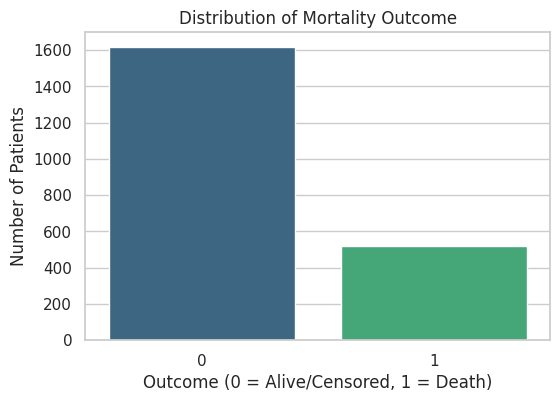

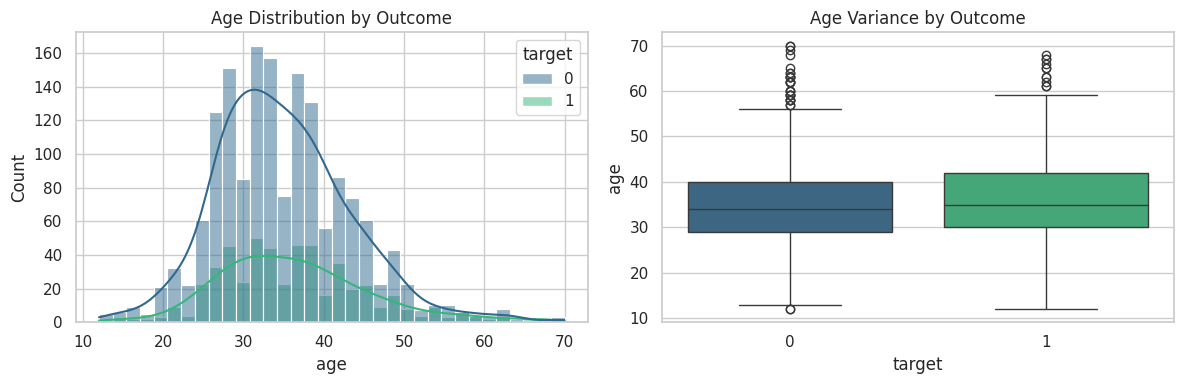

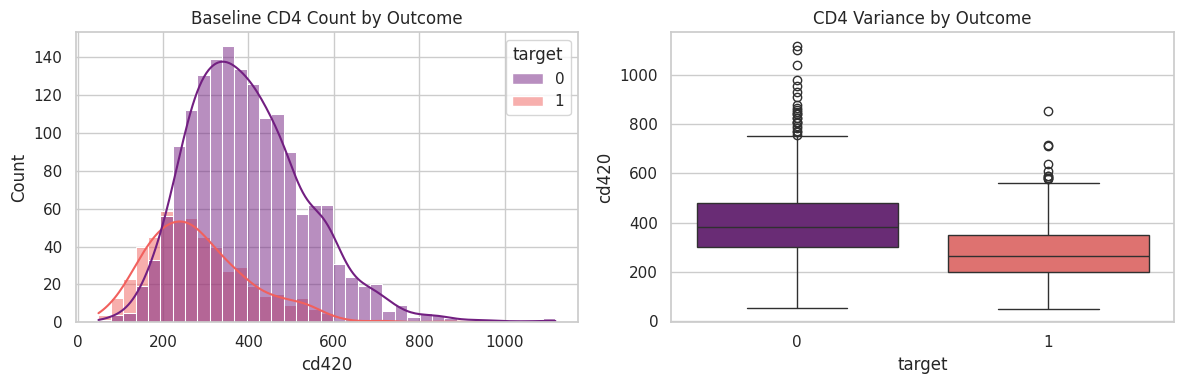

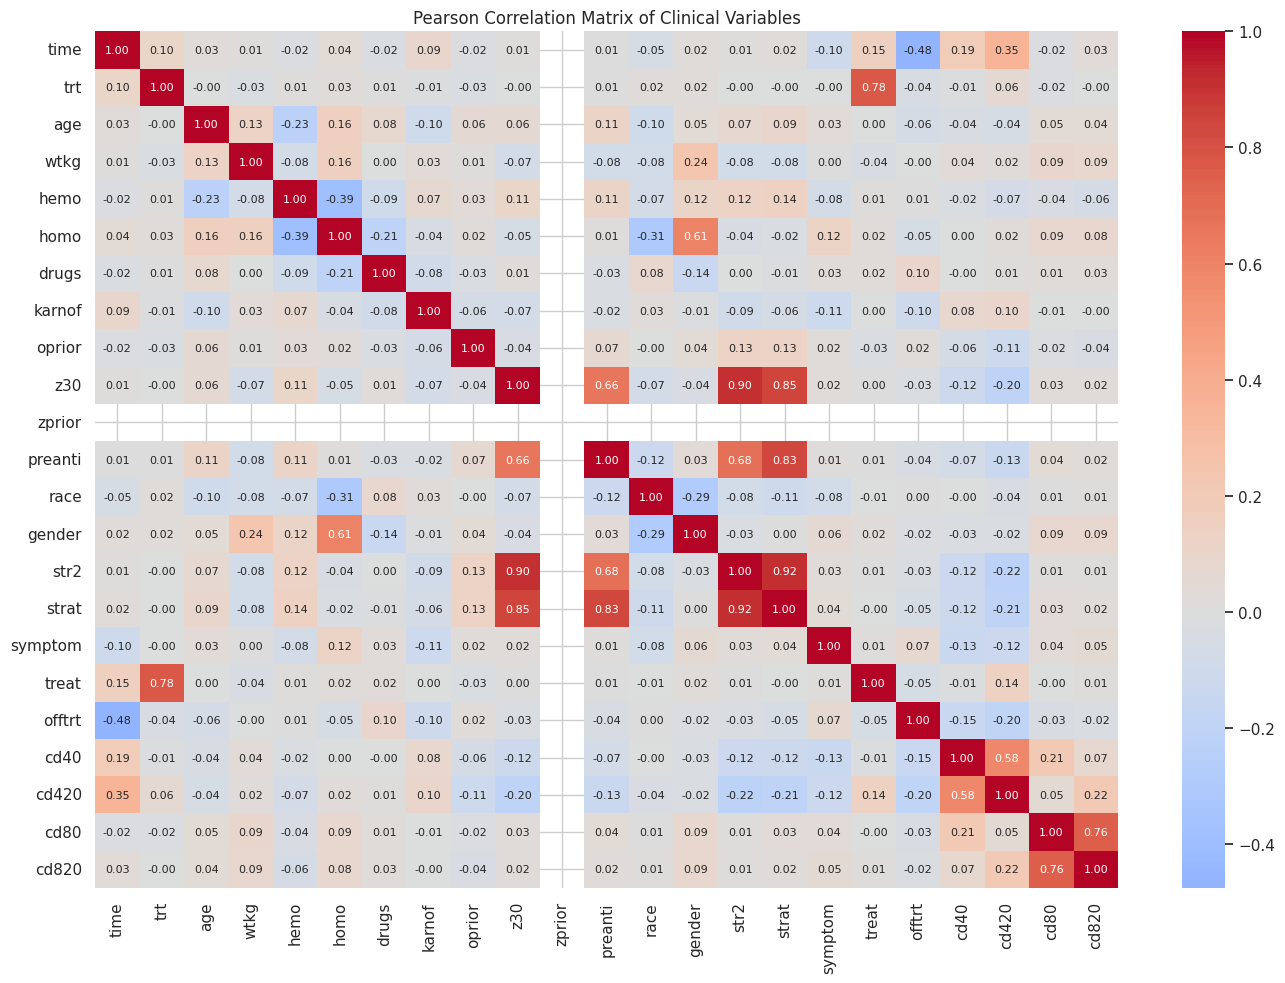

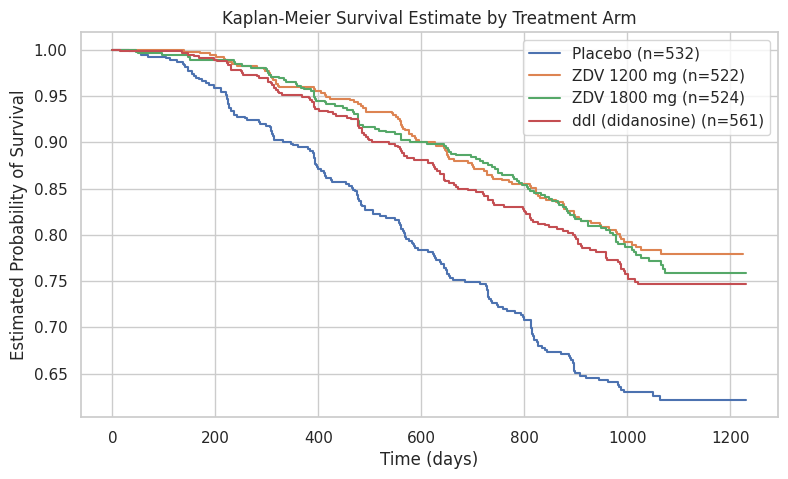


--- Step 4: Inferential Statistical Analysis ---


,Test,Statistic,p-value,Significant
0,Independent t-test (Age),-3.2618,0.0011,Yes
1,Chi-square (Gender),4.0802,0.0434,Yes
2,One-way ANOVA (CD4 by Treatment Arm),19.5098,0.0000,Yes



Result: The following tests show a statistically significant relationship with the outcome:
  - Independent t-test (Age) (p = 0.0011)
  - Chi-square (Gender) (p = 0.0434)
  - One-way ANOVA (CD4 by Treatment Arm) (p = 0.0000)

--- Step 5: Preprocessing & Feature Engineering ---
No categorical columns detected; skipping encoding.
Excluded 'time' from the predictors (used for survival analysis).
Created interaction feature: cd4_age_interaction
Preprocessing complete: features encoded, split, imputed, and scaled.

--- Step 6: Machine Learning Model Execution ---
Class imbalance detected (event rate = 24.4%); enabled class weighting for Logistic Regression.



,Accuracy,Precision,Recall,F1,AUC,CV AUC (mean)
Logistic Regression,0.7087,0.4411,0.7436,0.5537,0.7841,0.7481
Decision Tree,0.6931,0.3566,0.3269,0.3411,0.5688,0.5768
Random Forest,0.7897,0.6522,0.2885,0.4000,0.7398,0.7310
Gradient Boosting,0.7804,0.6000,0.2885,0.3896,0.7374,0.7359


Champion model based on AUC: Logistic Regression (AUC = 0.7841)
Selection rationale: the outcome is class-imbalanced, so ROC-AUC was chosen as the primary metric because it summarizes discrimination across all thresholds and is less affected by the majority class than accuracy.



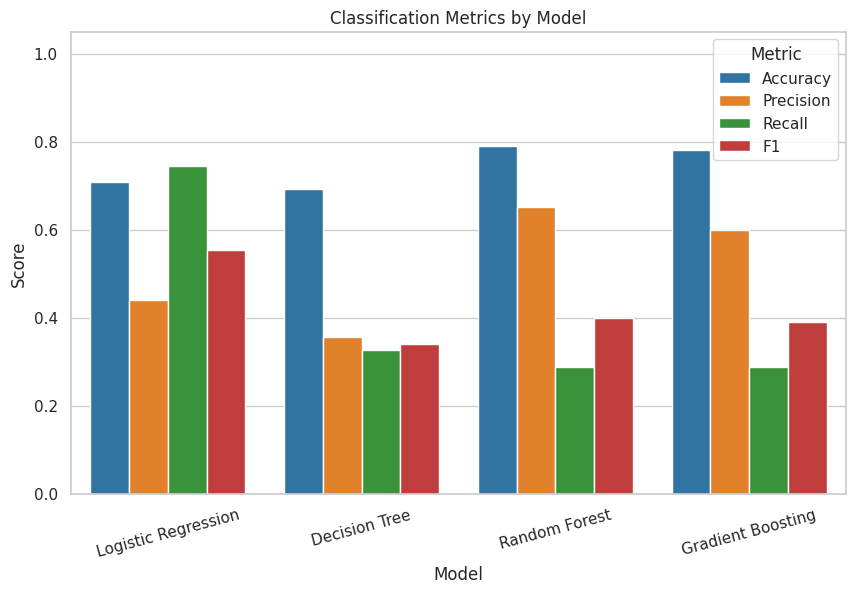

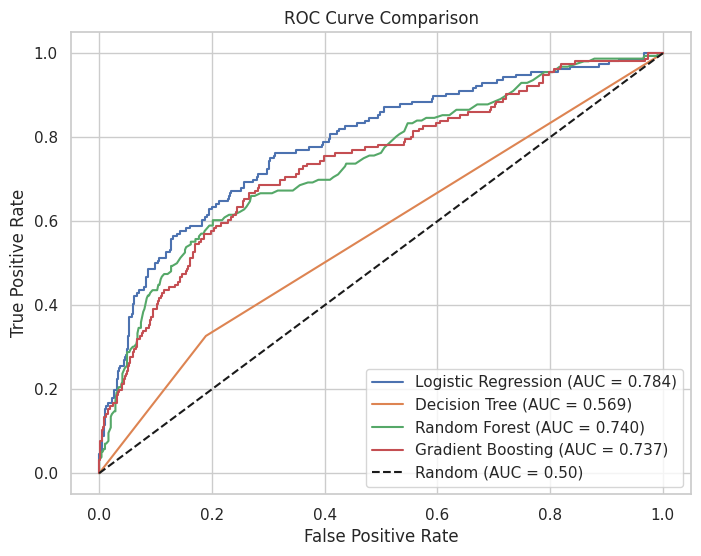

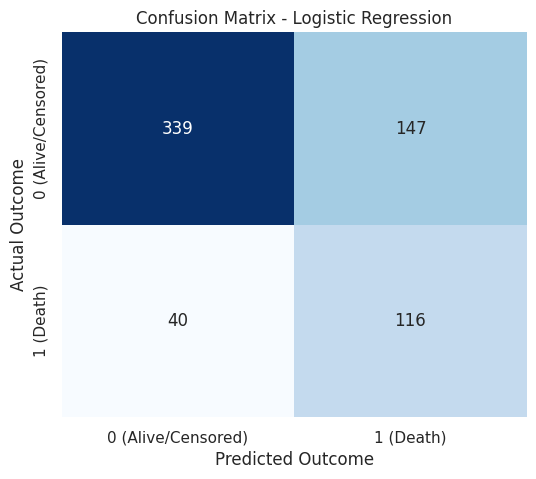

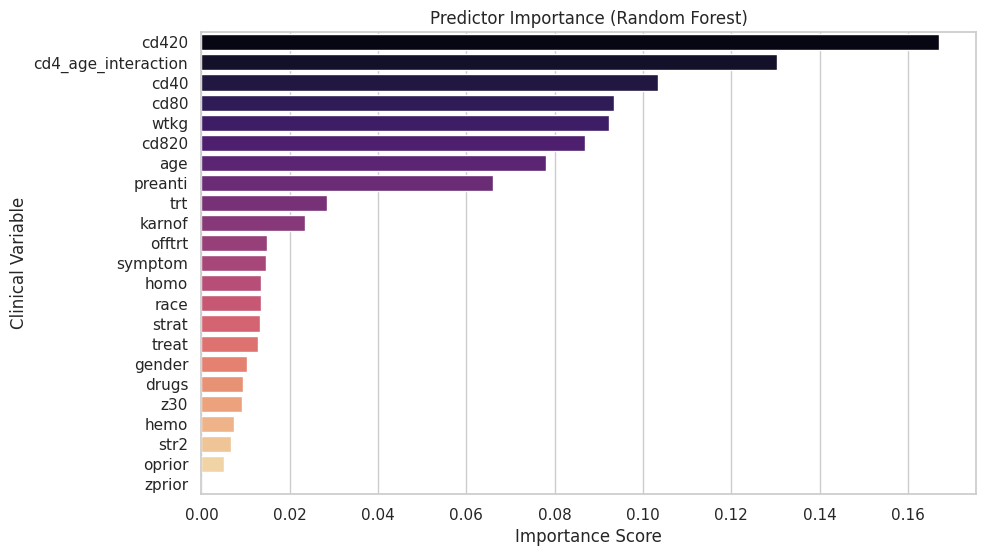

--- Step 7: Results Summary ---
1. Champion model (AUC): Logistic Regression (AUC = 0.7841)
2. Most important predictor (Random Forest): cd420
3. Interpretation: the champion model was selected automatically using the predefined primary metric, which removes subjectivity from model selection. The leading predictors align with the clinical literature, in which baseline immune status (CD4 count) and overall disease severity are the strongest drivers of mortality in people living with HIV.



In [4]:
# 4. PIPELINE EXECUTION

# Create a single pipeline instance that carries state between stages
pipeline = HealthAnalysisPipeline(CONFIG)

# Execute the full workflow in the defined sequence
pipeline.run()

### Interpretation of Results

#### Reading the Model Comparison Table
Each model is evaluated on the same held-out test set, so the metrics are directly comparable. Because roughly three-quarters of the cohort is alive/censored, a model that predicts "alive" for every patient would still reach about 75% accuracy. This is why the table pairs accuracy with precision, recall, F1, and ROC-AUC, and why the cross-validation column is included as a stability check on the single-split estimates.

#### Why ROC-AUC Is the Primary Metric
ROC-AUC summarizes a model's ability to rank higher-risk patients above lower-risk patients across every possible classification threshold. In a class-imbalanced clinical problem, that ranking quality is more informative than a single threshold-dependent accuracy score, so it was predefined as the metric used to select the champion model.

#### Clinical Context for the Confusion Matrix
For the champion model, the confusion matrix makes the clinical trade-off explicit. In this setting, a false negative — a patient at high risk of death predicted as alive — is more consequential than a false positive, because the former can delay intervention while the latter mostly adds monitoring. The matrix should be read alongside the recall value rather than the accuracy value alone.

#### Role of Feature Importance
The Random Forest importance plot identifies which baseline measurements drive the predictions. The leading predictors are expected to be clinically plausible (immune status and disease severity), which supports the model's interpretability. Feature importance reflects predictive association, not causation.

### Limitations and Future Directions

#### Limitations

- The analysis uses a single baseline snapshot; longitudinal laboratory values collected during follow-up are not used for prediction.
- The binary outcome collapses censored and deceased patients into one class. The Kaplan-Meier visualization uses the time-to-event information descriptively, but a full survival model (e.g., Cox proportional hazards) would be a more appropriate inferential framework.
- Performance is estimated from a single stratified split, mitigated but not replaced by the cross-validation check.
- Results are specific to the ACTG 175 trial population and may not generalize to other HIV cohorts or treatment eras.
- This analysis is for instructional purposes only and must not be used for individual clinical decision-making.

#### Future Directions

- Survival modeling with censored outcomes using the time-to-event variable
- Hyperparameter tuning with random or grid search
- Partial dependence and SHAP analyses for deeper model interpretation
- External validation on an independent clinical cohort

### References

- UCI Machine Learning Repository. "AIDS Clinical Trials Group Study 175 (ACTG 175)." https://archive.ics.uci.edu/ml/datasets/ACTG+175
- AIDS Clinical Trials Group. "A randomized, double-blind, placebo-controlled trial of antiretroviral therapy in patients with less than 200 CD4+ cells per cubic millimeter (ACTG 175)."

### Appendix: Method Documentation Summary

#### ingest_and_validate():
Loads the ACTG 175 dataset from the UCI repository or from a local file upload and performs initial data quality checks, including class balance, missing values, duplicate rows, clinical range validation, and confirmation that the outcome is binary.

#### run_descriptive():
Generates a descriptive statistics table for all numeric variables, reporting measures of central tendency and dispersion for the cohort.

#### run_eda():
Conducts exploratory data analysis through visualizations that examine the target distribution, age and CD4 count at 20 weeks by outcome, relationships among numeric predictors, and the survival experience by treatment arm.

#### run_inferential_stats():
Performs inferential statistical testing using an independent t-test for age, a chi-square test for gender, and a one-way ANOVA for CD4 at 20 weeks across treatment arms, and reports each result against the configured significance level.

#### preprocess_data():
Handles data preprocessing and feature engineering by encoding categorical variables, creating a CD4 at 20 weeks x age interaction term, splitting the data in a stratified 70/30 ratio, and imputing and scaling the predictors using statistics learned from the training set only.

#### train_and_evaluate():
Trains and evaluates the four machine learning models on the held-out test set, adds a cross-validation stability check, and programmatically selects the best-performing model using the predefined primary metric.

#### plot_model_comparison(), plot_roc_curves(), plot_confusion_matrix(), plot_feature_importance():
Produce the comparative visualizations that support interpretation of the results, including a grouped metric comparison, an ROC curve overlay, a confusion matrix for the champion model, and the Random Forest predictor importances.

#### summarize():
Prints a plain-language summary of the champion model, the top predictor, and a short clinical interpretation of the findings.